# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
!pip install statsforecast

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [statsforecast]


In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsforecast.arima import ARIMASummary, ndiffs, nsdiffs
from statsforecast.models import ARIMA, AutoARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "YEFIMOVA"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [3]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [4]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [5]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

In [6]:
def difference_plan(series: np.ndarray, m: int, log: bool = False):
    # Step 1: D from seasonal strength, then d from KPSS on what is left. Returns D, d and the differenced series.
    x = np.log(series) if log else np.asarray(series, float)
    D = nsdiffs(x, period=m)
    z = x[m:] - x[:-m] if D else x.copy()
    d = ndiffs(z)
    z = np.diff(z, n=d) if d else z
    print(f"{'log, ' if log else ''}D = {D}, d = {d}: {len(x)} observations -> {len(z)} after differencing")
    return D, d, z


def acf_pacf(z: np.ndarray, lags: int, title: str = ""):
    # Step 2: read p, q at lags 1, 2, 3 and P, Q at lags m, 2m, 3m (shaded).
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    plot_acf(z, lags=lags, zero=False, ax=axes[0], auto_ylims=True, title=f"{title} ACF")
    plot_pacf(z, lags=lags, zero=False, ax=axes[1], auto_ylims=True, title=f"{title} PACF")
    for ax in axes:
        for k in range(M, lags + 1, M):
            ax.axvline(k, color="#e64173", alpha=0.25, linewidth=6)
    plt.show()


def mase(actual, forecast) -> float:
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast))) / SCALE)


def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


class Fitted:
    # A fitted ARIMA whose forecasts are on the original scale, whatever it was fitted on.
    def __init__(self, model, log):
        self.model, self.log = model, log
        self.model_ = model.model_

    def predict(self, h: int, level=None):
        out = self.model.predict(h=h, level=level)
        return {k: np.exp(v) for k, v in out.items()} if self.log else out


def fit_arima(history: np.ndarray, order=None, seasonal=(0, 0, 0), log: bool = False,
              drift: bool = False) -> Fitted:
    # order=(p, d, q) and seasonal=(P, D, Q) for a hand specification; order=None lets AutoARIMA search.
    x = np.log(history) if log else np.asarray(history, float)
    if order is None:
        model = AutoARIMA(season_length=M)
    else:
        model = ARIMA(order=tuple(order), seasonal_order=tuple(seasonal), season_length=M,
                      include_drift=drift and (order[1] + seasonal[1]) == 1)
    model.fit(y=x)
    return Fitted(model, log)


def compare(candidates: dict, history: np.ndarray, lb_lags: int | None = None) -> pd.DataFrame:
    # Step 3: every candidate fitted on `history`; AICc and Ljung-Box with model_df = p + q + P + Q.
    # AICc is comparable only between candidates with the same d, D and log choice.
    lb_lags = lb_lags or 2 * M
    rows = []
    for name, spec in candidates.items():
        fit = fit_arima(history, **spec)
        p, q, P, Q = fit.model_["arma"][:4]
        resid = pd.Series(fit.model_["residuals"])
        rows.append({"candidate": name,
                     "model": ("log " if fit.log else "") + str(ARIMASummary(fit.model_)).strip(),
                     "AICc": fit.model_["aicc"],
                     f"Ljung-Box p ({lb_lags})": acorr_ljungbox(resid, lags=[lb_lags], model_df=p + q + P + Q)["lb_pvalue"].iloc[0],
                     f"resid acf({M})": resid.autocorr(M),
                     "valid RMSE": rmse(valid, fit_arima(train, **spec).predict(h=H)["mean"])})
    return pd.DataFrame(rows)


def rolling_rmse(spec: dict, history: np.ndarray, h: int, windows: int = 3) -> float:
    # Середнє RMSE за `windows` вікон; останнє вікно — це валідаційне вікно.
    errors = []
    for k in range(windows):
        end = len(history) - k * h
        fit = fit_arima(history[:end - h], **spec)
        errors.append(rmse(history[end - h:end], fit.predict(h=h)["mean"]))
    return float(np.mean(errors))

In [7]:
# ============================================================
# Вставте в зошит ПІСЛЯ комірок з функціями (rmse, winkler, score, snaive, fit_arima)
# і після завантаження data / weather_fc.
# ============================================================
import numpy as np
import pandas as pd
from statsforecast.models import ARIMA

# ---------- 1. Налаштування ----------
SPEC = {"order": (1, 0, 0), "seasonal": (0, 1, 1), "log": False}   # ваша поточна модель
TRAIN_DAYS_GRID = [7, 14, 21, 28, 42]     # кандидати: скільки ОСТАННІХ днів брати для навчання
N_WINDOWS = 12                             # кількість 48-год вікон для валідації
EXOG_COLS = None                           # None = без погоди; або ["cloud_cover", "daylight", "wind_speed", "temperature"]

y = data["y"].to_numpy(float)
X_all = data[EXOG_COLS].to_numpy(float) if EXOG_COLS else None


# ---------- 2. Одна функція "навчити і спрогнозувати" (з погодою або без) ----------
def fit_predict(y_tr, spec, h, X_tr=None, X_te=None):
    x = np.log(y_tr) if spec["log"] else np.asarray(y_tr, float)
    m = ARIMA(order=tuple(spec["order"]), seasonal_order=tuple(spec["seasonal"]), season_length=M)
    m.fit(y=x, X=X_tr)
    out = m.predict(h=h, X=X_te, level=[95])
    return {k: np.exp(v) for k, v in out.items()} if spec["log"] else out


# ---------- 3. Rolling-валідація: ті самі вікна для всіх кандидатів ----------
def rolling_eval(spec, train_days, n_windows=N_WINDOWS, h=H):
    rows, z = [], []
    for k in range(n_windows):
        end = len(y) - k * h                         # вікна не перетинаються, йдуть назад від кінця
        start = end - h - 24 * train_days            # <-- тут працює змінна train_days
        Xtr = X_all[start:end - h] if X_all is not None else None
        Xte = X_all[end - h:end] if X_all is not None else None
        out = fit_predict(y[start:end - h], spec, h, Xtr, Xte)
        f = np.clip(out["mean"], 0, None)
        lo, hi = out["lo-95"], out["hi-95"]
        a = y[end - h:end]
        rows.append(score(a, f, np.clip(lo, 0, None), hi))
        z.append(np.abs(a - f) / np.maximum((hi - lo) / 2, 1e-6))   # помилка у "півширинах" інтервалу
    return pd.DataFrame(rows).mean(), np.concatenate(z)


results, Z = {}, {}
for td in TRAIN_DAYS_GRID:
    results[f"SARIMA, {td} днів"], Z[td] = rolling_eval(SPEC, td)

# бенчмарк на ТИХ САМИХ вікнах (щоб чесно порівняти)
bench_rows = []
for k in range(N_WINDOWS):
    end = len(y) - k * H
    p, lo, hi = snaive(y[:end - H])
    bench_rows.append(score(y[end - H:end], p, lo, hi))
results["seasonal naive"] = pd.DataFrame(bench_rows).mean()

table = pd.DataFrame(results).T
display(table.sort_values("RMSE"))

# ---------- 4. Обираємо вікно навчання ----------
TRAIN_DAYS = int(min(TRAIN_DAYS_GRID, key=lambda td: table.loc[f"SARIMA, {td} днів", "RMSE"]))
print("Обране вікно навчання:", TRAIN_DAYS, "днів")

# ---------- 5. Фінальна модель на останніх TRAIN_DAYS днях ----------
n_tr = 24 * TRAIN_DAYS
y_train = y[-n_tr:]                                           # <-- змінна, на якій тренуємо
X_train = X_all[-n_tr:] if X_all is not None else None
X_future = weather_fc[EXOG_COLS].to_numpy(float) if EXOG_COLS else None

out = fit_predict(y_train, SPEC, H, X_train, X_future)
f = np.clip(out["mean"], 0, None)
half = (out["hi-95"] - out["lo-95"]) / 2

# калібровка ширини інтервалу: коефіцієнт, при якому у валідації покриття ≈ 95%
kappa = float(np.quantile(Z[TRAIN_DAYS], 0.95))
print(f"коефіцієнт калібровки інтервалу kappa = {kappa:.2f} (1 = інтервал моделі вже ок)")

forecast = f
lower_95 = np.clip(f - kappa * half, 0, None)
upper_95 = f + kappa * half
# далі йде ваша клітинка Submission (графік, check_submission, збереження файлу)

,RMSE,MAPE,Winkler,coverage
"SARIMA, 7 днів",272.935,177.405,1239.954,0.946
"SARIMA, 14 днів",289.999,220.957,1336.832,0.943
seasonal naive,292.544,364.151,2117.314,0.790
"SARIMA, 21 днів",297.948,239.010,1423.287,0.931
"SARIMA, 28 днів",306.925,240.533,1453.360,0.924
"SARIMA, 42 днів",315.379,244.755,1569.453,0.898


Обране вікно навчання: 7 днів
коефіцієнт калібровки інтервалу kappa = 1.01 (1 = інтервал моделі вже ок)


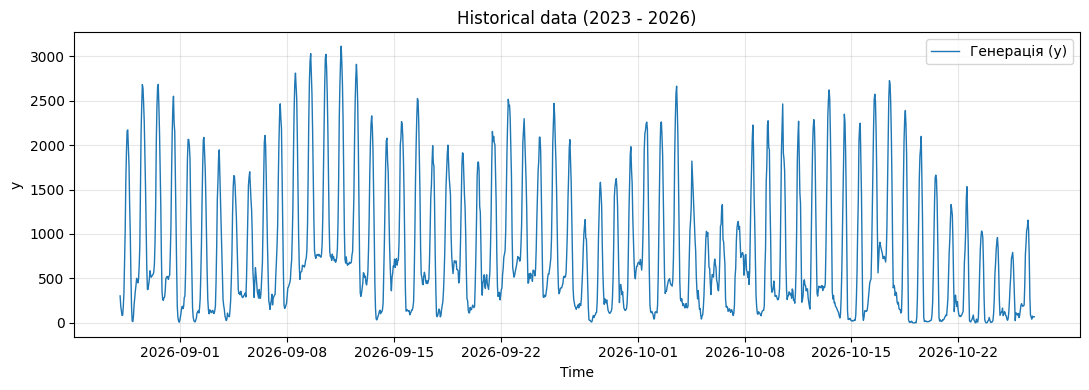

In [8]:
plt.figure(figsize=(11, 4))
plt.plot(data['ds'].tail(24 * 60), data['y'].tail(24 * 60), color='tab:blue', linewidth=1, label='Генерація (y)')
plt.title('Historical data (2023 - 2026)')
plt.xlabel('Time')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

бачимо денну сезонність

Оптимальний параметр lambda: 0.1518


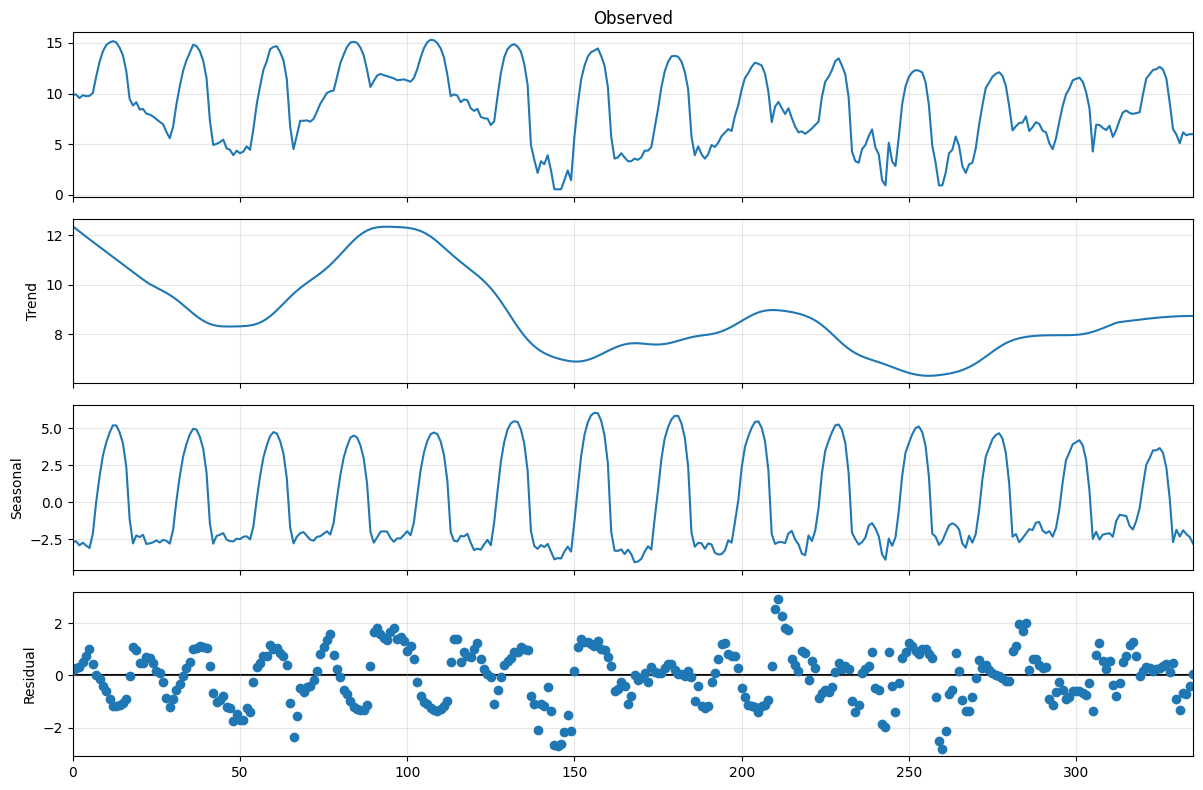

In [9]:
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# Припускаємо, що y_subset вже визначено як pd.Series
# Додаємо константу, оскільки перетворення Бокса-Кокса вимагає строго додатних значень
y_subset = data.set_index("ds")["y"].iloc[-24 * 14:]
y_shifted = y_subset + 1

# 1. Перетворення Бокса-Кокса
# Функція повертає трансформований масив та оптимальний параметр lambda
y_transformed, lmbda = boxcox(y_shifted)
print(f"Оптимальний параметр lambda: {lmbda:.4f}")

# 2. STL-декомпозиція на стабілізованих даних
stl = STL(y_transformed, period=24)
result_stl = stl.fit()

# Візуалізація стабілізованих компонентів
fig = result_stl.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

# 3. Приклад зворотного перетворення (використовуй для точкових прогнозів та меж інтервалів)
# Віднімаємо 1, щоб повернутися до оригінальної шкали генерації (у МВт)
y_inverted = inv_boxcox(y_transformed, lmbda) - 1

In [10]:
import numpy as np
import pandas as pd
from scipy.stats import boxcox_normmax, spearmanr

M = 24
y = data["y"].to_numpy(float)
if (y <= 0).any():
    print("є нулі або від'ємні значення, зсуваю на +1 для Box-Cox")
    y = y + 1

# перевірка масштабу: добові максимуми за останні 60 діб
daily_max = pd.Series(y, index=data["ds"]).resample("D").max()
print(daily_max.tail(60).describe().round(1))

# пошук λ
n_days = len(y) // M
Yd = y[-n_days * M:].reshape(n_days, M)
lvl = Yd.mean(axis=1)

def boxcox_t(v, lam):
    return np.log(v) if abs(lam) < 1e-8 else (v ** lam - 1) / lam

rows = []
for lam in np.round(np.arange(-0.5, 1.01, 0.05), 2):
    T = boxcox_t(Yd, lam)
    rng = T.max(axis=1) - T.min(axis=1)
    rows.append((lam, spearmanr(lvl, rng).correlation))
res = pd.DataFrame(rows, columns=["lambda", "spearman(рівень, розмах)"])
print(res.round(3).to_string(index=False))

best = res.loc[res["spearman(рівень, розмах)"].abs().idxmin(), "lambda"]
print(f"λ, при якому розмах найменш залежить від рівня: {best}")
print(f"λ за максимумом правдоподібності (boxcox_normmax): {boxcox_normmax(y):.3f}")

count      60.0
mean     2052.9
std       609.6
min        69.9
25%      1689.6
50%      2129.7
75%      2464.3
max      3111.3
dtype: float64
 lambda  spearman(рівень, розмах)
  -0.50                    -0.602
  -0.45                    -0.587
  -0.40                    -0.570
  -0.35                    -0.551
  -0.30                    -0.527
  -0.25                    -0.500
  -0.20                    -0.468
  -0.15                    -0.429
  -0.10                    -0.384
  -0.05                    -0.330
  -0.00                    -0.267
   0.05                    -0.193
   0.10                    -0.108
   0.15                    -0.013
   0.20                     0.088
   0.25                     0.188
   0.30                     0.276
   0.35                     0.349
   0.40                     0.410
   0.45                     0.463
   0.50                     0.510
   0.55                     0.551
   0.60                     0.588
   0.65                     0.622
   0.70

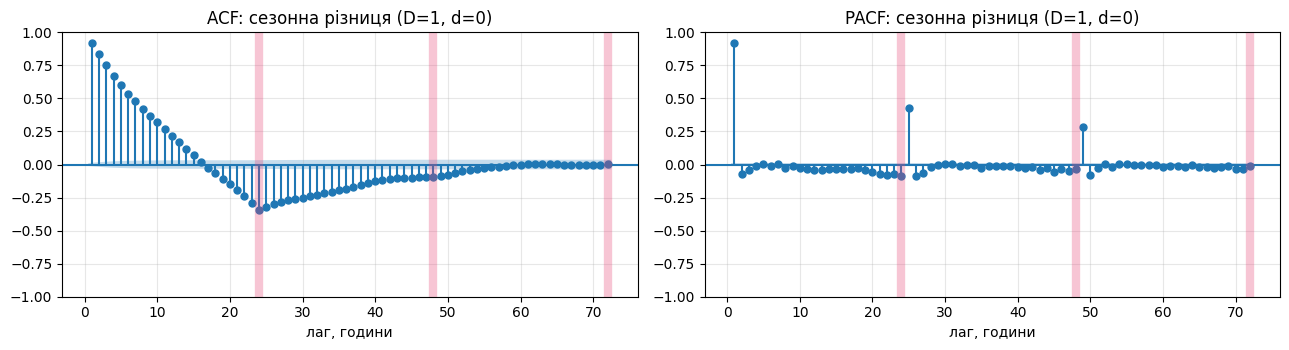

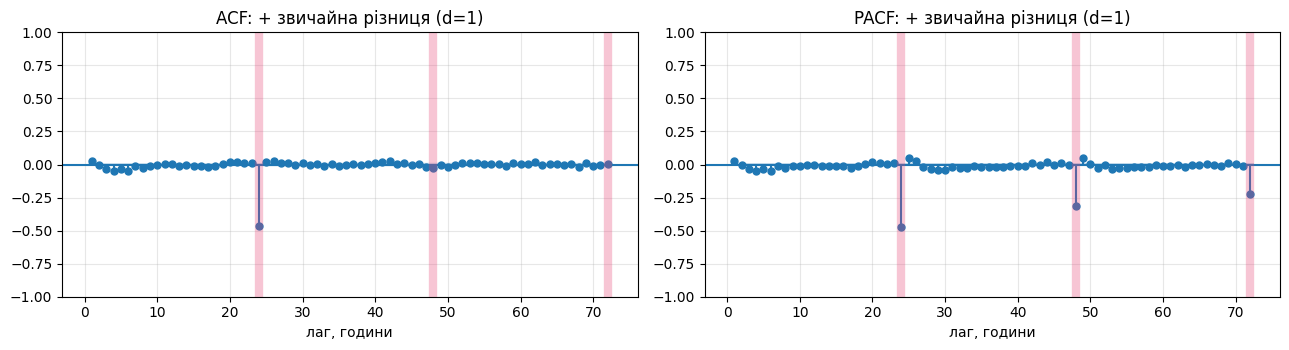

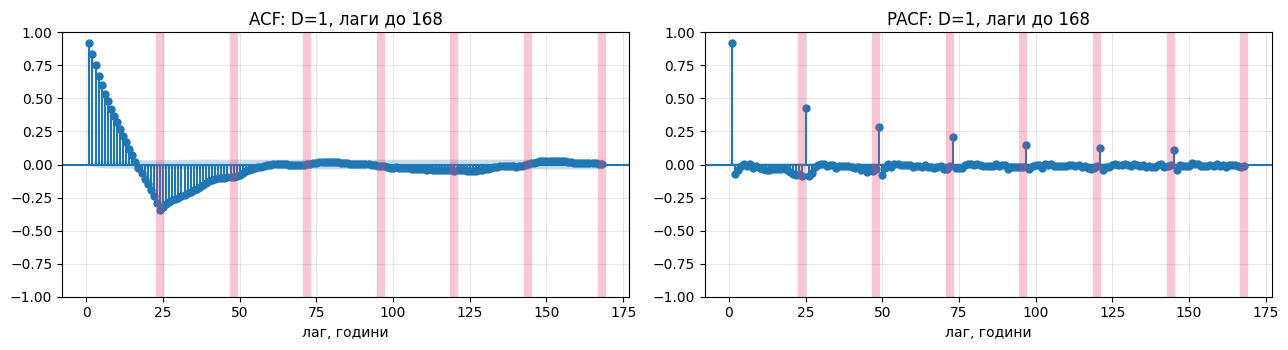

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

M = 24                 # доба

y = data["y"].to_numpy(float)          # сирі значення, без перетворення
zs = y[M:] - y[:-M]                    # сезонна різниця D = 1, лаг 24
zd = np.diff(zs)                       # додатково звичайна різниця d = 1

def plot_pair(series, title, lags):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    plot_acf(series, lags=lags, zero=False, ax=axes[0], title=f"ACF: {title}")
    plot_pacf(series, lags=lags, zero=False, method="ywm", ax=axes[1],
              title=f"PACF: {title}")
    for ax in axes:
        for k in range(M, lags + 1, M):          # сезонні лаги 24, 48, 72 підсвічено
            ax.axvline(k, color="#e64173", alpha=0.3, linewidth=6)
        ax.set_xlabel("лаг, години")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# 1. Основний варіант: D = 1, d = 0 (сирі значення)
plot_pair(zs, "сезонна різниця (D=1, d=0)", lags=72)

# 2. Для порівняння: додатково d = 1
plot_pair(zd, "+ звичайна різниця (d=1)", lags=72)

# 3. Довгі лаги до тижня: чи є сигнал на лагу 168
plot_pair(zs, "D=1, лаги до 168", lags=168)

In [12]:
import warnings
import numpy as np
import pandas as pd
from scipy.special import inv_boxcox
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

H, M = 48, 24
N_WINDOWS = 7            # 14 діб тесту: 7 вікон по 48 годин (для 7 діб — 3 або 4)
LAM, SHIFT = 0.19, 1
W_COLS = ["cloud_cover", "temperature", "wind_speed"]

CANDIDATES = {
    "A: ARIMA(1,1,1)(3,1,1), 7д, без погоди":   dict(order=(3, 0, 0), seasonal=(0, 1, 3), exog=None,   train_days=7),
    "B: ARIMA(1,1,1)(3,1,1)+погода, 7д":        dict(order=(3, 0, 0), seasonal=(0, 1, 3), exog=W_COLS, train_days=7),
    "C: ARIMA(1,1,1)(3,1,1), 14д, без погоди":  dict(order=(3, 0, 0), seasonal=(0, 1, 3), exog=None,   train_days=14),
    "D: ARIMA(1,1,1)(3,1,1)+погода, 14д":       dict(order=(3, 0, 0), seasonal=(0, 1, 3), exog=W_COLS, train_days=14),
}

Y = data["y"].to_numpy(float)
X_obs = data[W_COLS].to_numpy(float)


def bc(v):
    v = np.asarray(v, float) + SHIFT
    return np.log(v) if LAM == 0 else (v ** LAM - 1) / LAM


def bc_inv(t):
    return inv_boxcox(np.asarray(t, float), LAM) - SHIFT


def rmse(a, f):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))


def winkler(a, lo, hi, alpha=0.05):
    a, lo, hi = (np.asarray(v, float) for v in (a, lo, hi))
    below = np.clip(lo - a, 0, None)
    above = np.clip(a - hi, 0, None)
    return float(np.mean((hi - lo) + 2 / alpha * (below + above)))


def fit_forecast(y_tr, X_tr, X_te, spec):
    z = bc(y_tr)
    if X_tr is not None:
        mu, sd = X_tr.mean(axis=0), X_tr.std(axis=0) + 1e-9
        X_tr, X_te = (X_tr - mu) / sd, (X_te - mu) / sd
    res = SARIMAX(z, exog=X_tr, order=spec["order"], seasonal_order=spec["seasonal"] + (M,),
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = res.get_forecast(steps=H, exog=X_te)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    mean = np.clip(bc_inv(np.asarray(fc.predicted_mean)), 0, None)
    lo = np.clip(bc_inv(ci[:, 0]), 0, None)
    hi = bc_inv(ci[:, 1])
    return mean, lo, hi


def window_forecast(spec, o, weather_mode="observed"):
    n_tr = M * spec["train_days"]
    y_tr = Y[o - n_tr:o]
    if spec["exog"] is None:
        return fit_forecast(y_tr, None, None, spec)
    X_tr = X_obs[o - n_tr:o]
    if weather_mode == "observed":          # фактична погода: оптимістична межа
        X_te = X_obs[o:o + H]
    else:                                   # остання відома погода повторюється: песимістична межа
        X_te = np.repeat(X_obs[o - 1:o], H, axis=0)
    return fit_forecast(y_tr, X_tr, X_te, spec)


def collect(predict_fn, n_windows=N_WINDOWS):
    out = {"F": [], "LO": [], "HI": [], "A": []}
    for k in range(n_windows):
        o = len(Y) - (k + 1) * H
        a = Y[o:o + H]
        try:
            f, lo, hi = predict_fn(o)
            if not (np.isfinite(f).all() and np.isfinite(lo).all() and np.isfinite(hi).all()):
                raise ValueError("NaN")
        except Exception:
            f = lo = hi = np.full(H, np.nan)
        out["F"].append(f); out["LO"].append(lo); out["HI"].append(hi); out["A"].append(a)
    return {k: np.array(v) for k, v in out.items()}


def per_window(P):
    rows = []
    for k, (f, lo, hi, a) in enumerate(zip(P["F"], P["LO"], P["HI"], P["A"])):
        if np.isnan(f).any():
            rows.append(dict(k=k, rmse=np.nan, wink=np.nan, cov=np.nan, width=np.nan))
        else:
            rows.append(dict(k=k, rmse=rmse(a, f), wink=winkler(a, lo, hi),
                             cov=float(((a >= lo) & (a <= hi)).mean()),
                             width=float((hi - lo).mean())))
    return pd.DataFrame(rows).set_index("k")


def compare_models(models, baseline="Наївний"):
    PW = {n: per_window(P) for n, P in models.items()}
    common = np.all([PW[n]["rmse"].notna().values for n in PW], axis=0)
    base = PW[baseline].loc[common]
    rows = []
    for n, pw in PW.items():
        r = pw.loc[common]
        d = r["rmse"].values - base["rmse"].values
        rows.append({
            "модель": n,
            "RMSE": r["rmse"].mean(),
            "Winkler": r["wink"].mean(),
            "покриття": r["cov"].mean(),
            "|покриття−0.95|": abs(r["cov"].mean() - 0.95),
            "ширина, МВт": r["width"].mean(),
            "Δ RMSE vs наївний": d.mean(),
            "±95% Δ": 1.96 * d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan,
            "частка вікон краще наївного": float((d < 0).mean()),
        })
    return pd.DataFrame(rows).set_index("модель"), int(common.sum())


# ---------- запуск ----------
models = {"Наївний": collect(lambda o: snaive(Y[:o]))}
for name, spec in CANDIDATES.items():
    models[name] = collect(lambda o, s=spec: window_forecast(s, o, "observed"))
    if spec["exog"] is not None:
        models[name + " [погода: персистентна]"] = collect(
            lambda o, s=spec: window_forecast(s, o, "persistence"))

table, n_common = compare_models(models)
print(f"спільних вікон: {n_common} з {N_WINDOWS}")
display(table.round(3).sort_values("RMSE"))

# models — той самий формат (F, LO, HI, A), що й у ансамблі, тож можна передати далі

спільних вікон: 6 з 7


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"B: ARIMA(1,1,1)(3,1,1)+погода, 7д",219.303,1844.050,0.875,0.075,1598.795,-27.202,107.031,0.500
"B: ARIMA(1,1,1)(3,1,1)+погода, 7д [погода: персистентна]",233.330,1825.540,0.896,0.054,1592.252,-13.175,112.501,0.333
Наївний,246.505,1572.469,0.833,0.117,630.360,0.000,0.000,0.000
"A: ARIMA(1,1,1)(3,1,1), 7д, без погоди",266.035,1993.301,0.892,0.058,1750.489,19.530,126.041,0.333
"E: ARIMA(1,1,1)(3,1,1), 60д, без погоди",313.492,1702.682,0.882,0.068,1613.620,66.987,154.596,0.333
"D: ARIMA(1,1,1)(3,1,1)+погода, 14д",322.369,1754.548,0.903,0.047,1670.768,75.864,161.758,0.500
"D: ARIMA(1,1,1)(3,1,1)+погода, 14д [погода: персистентна]",324.445,1689.151,0.889,0.061,1598.068,77.940,175.345,0.333
"C: ARIMA(1,1,1)(3,1,1), 14д, без погоди",355.927,1878.589,0.899,0.051,1773.280,109.422,191.109,0.333


In [13]:
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

Y_full = np.concatenate([Y, np.full(H, np.nan)])
W_full = np.vstack([data[W_COLS].to_numpy(float), weather_fc[W_COLS].to_numpy(float)])
ds_full = pd.concat([data["ds"], weather_fc["ds"]]).reset_index(drop=True)
hod_full = ds_full.dt.hour.to_numpy()
dow_full = ds_full.dt.dayofweek.to_numpy()


def features(p):
    i = np.arange(H)
    t = p + i
    base = np.maximum(np.mean([Y_full[p + (i % M) - M * d] for d in (1, 2, 3)], axis=0), 1.0)
    cols = {
        "h": i, "hod": hod_full[t], "dow": dow_full[t],
        "lag48": Y_full[t - 48] / base, "lag72": Y_full[t - 72] / base,
        "lag96": Y_full[t - 96] / base, "lag168": Y_full[t - 168] / base,
        "last_rel": Y_full[p - 1] / base,
        "mean24_rel": Y_full[p - 24:p].mean() / base,
    }
    for j, c in enumerate(W_COLS):
        cols[c] = W_full[t, j]
    return pd.DataFrame(cols), base


def train_set(o, train_days):
    Xs, Ys, Bs = [], [], []
    for p in range(o - 24 * train_days, o - H + 1):
        X, base = features(p)
        Xs.append(X); Ys.append(Y_full[p:p + H] / base); Bs.append(base)
    return pd.concat(Xs, ignore_index=True), np.concatenate(Ys), np.concatenate(Bs)


def lgb_point(o, td=14):
    Xtr, ytr, btr = train_set(o, td)
    Xte, bte = features(o)
    m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, verbose=-1)
    m.fit(Xtr, ytr, sample_weight=btr ** 2)
    return np.clip(m.predict(Xte) * bte, 0, None)


def ridge_point(o, td=14):
    Xtr, ytr, btr = train_set(o, td)
    Xte, bte = features(o)
    sc = StandardScaler().fit(Xtr)
    m = Ridge(alpha=1.0).fit(sc.transform(Xtr), ytr, sample_weight=btr ** 2)
    return np.clip(m.predict(sc.transform(Xte)) * bte, 0, None)


def avg_k(o, k=3):
    hist = Y[:o]
    n = len(hist)
    return np.array([np.mean([hist[n + (i % M) - M * d] for d in range(1, k + 1)]) for i in range(H)])


def collect_point(fn, n_windows=N_WINDOWS):
    F, A = [], []
    for k in range(n_windows):
        o = len(Y) - (k + 1) * H
        A.append(Y[o:o + H])
        try:
            f = np.asarray(fn(o), float)
            if not np.isfinite(f).all():
                raise ValueError("NaN")
        except Exception as e:
            print(f"вікно {k}: {repr(e)[:120]}")
            f = np.full(H, np.nan)
        F.append(f)
    return {"F": np.array(F), "A": np.array(A)}


def empirical_bands(P, n_cal=10):
    """Інтервал = точковий прогноз ± 95% квантиль |похибки| з попередніх (старших) вікон."""
    F, A = P["F"].copy(), P["A"]
    N = len(F)
    LO, HI = np.full_like(F, np.nan), np.full_like(F, np.nan)
    for k in range(N):
        cal = [j for j in range(k + 1, min(k + 1 + n_cal, N)) if np.isfinite(F[j]).all()]
        if not cal or not np.isfinite(F[k]).all():
            F[k] = np.nan          # немає старших вікон — вікно виключаємо з порівняння
            continue
        q = np.quantile(np.abs(A[cal] - F[cal]), 0.95)
        LO[k] = np.clip(F[k] - q, 0, None)
        HI[k] = F[k] + q
    return {"F": F, "LO": LO, "HI": HI, "A": A}


point_models = {
    "Наївний":        lambda o: snaive(Y[:o])[0],
    "Середнє 3 доби": lambda o: avg_k(o, 3),
    "Ridge 14д":     lambda o: ridge_point(o, 14),
    "Ridge 7д":     lambda o: ridge_point(o, 7),
    "LightGBM 14д":  lambda o: lgb_point(o, 14),
    "LightGBM 21д":  lambda o: lgb_point(o, 21),
}

PB = {name: empirical_bands(collect_point(fn)) for name, fn in point_models.items()}

# SARIMA з власними інтервалами — для порівняння поряд
merged = {**models, **PB}
table, n_common = compare_models(merged)
print(f"спільних вікон: {n_common} з {N_WINDOWS}")
display(table.round(3).sort_values("Winkler"))

спільних вікон: 5 з 7


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
LightGBM 14д,223.097,919.508,0.996,0.046,912.974,-20.062,62.300,0.6
Ridge 14д,238.311,1118.889,0.988,0.038,1078.237,-4.849,60.056,0.4
Наївний,243.160,1181.413,0.979,0.029,1113.992,0.000,0.000,0.0
Ridge 7д,332.900,1324.061,0.929,0.021,1051.355,89.740,120.066,0.2
Середнє 3 доби,311.736,1483.912,0.904,0.046,991.151,68.576,96.586,0.2
LightGBM 21д,311.694,1534.054,0.942,0.008,1027.096,68.534,131.754,0.4
"E: ARIMA(1,1,1)(3,1,1), 60д, без погоди",317.923,1689.314,0.883,0.067,1622.027,74.764,188.419,0.4
"D: ARIMA(1,1,1)(3,1,1)+погода, 14д [погода: персистентна]",317.311,1693.034,0.900,0.050,1654.031,74.152,214.561,0.4
"D: ARIMA(1,1,1)(3,1,1)+погода, 14д",341.347,1755.713,0.912,0.037,1717.337,98.187,190.728,0.4


In [14]:
def ridge_point(o, td=14, weather="observed"):
    Xtr, ytr, btr = train_set(o, td)
    Xte, bte = features(o)
    if weather == "none":
        Xtr = Xtr.drop(columns=W_COLS)
        Xte = Xte.drop(columns=W_COLS)
    elif weather == "persistent":
        Xte[W_COLS] = W_full[o - 1]     # остання відома погода повторюється
    sc = StandardScaler().fit(Xtr)
    m = Ridge(alpha=1.0).fit(sc.transform(Xtr), ytr, sample_weight=btr ** 2)
    return np.clip(m.predict(sc.transform(Xte)) * bte, 0, None)


ridge_variants = {
    "Ridge 14д, без погоди":   lambda o: ridge_point(o, 14, "none"),
    "Ridge 14д, персистентна": lambda o: ridge_point(o, 14, "persistent"),
    "Ridge 21д, без погоди":    lambda o: ridge_point(o, 21, "none"),
}
for name, fn in ridge_variants.items():
    PB[name] = empirical_bands(collect_point(fn))

table, n_common = compare_models({**models, **PB, "Наївний": PB["Наївний"]})
print(f"спільних вікон: {n_common} з {N_WINDOWS}")
display(table.round(3).sort_values("Winkler"))

спільних вікон: 5 з 7


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
LightGBM 14д,223.097,919.508,0.996,0.046,912.974,-20.062,62.300,0.6
Ridge 14д,238.311,1118.889,0.988,0.038,1078.237,-4.849,60.056,0.4
Наївний,243.160,1181.413,0.979,0.029,1113.992,0.000,0.000,0.0
"Ridge 14д, персистентна",256.854,1238.916,0.988,0.038,1209.579,13.694,88.778,0.2
Ridge 7д,332.900,1324.061,0.929,0.021,1051.355,89.740,120.066,0.2
Середнє 3 доби,311.736,1483.912,0.904,0.046,991.151,68.576,96.586,0.2
"Ridge 21д, без погоди",400.312,1508.747,0.979,0.029,1384.683,157.152,105.837,0.0
LightGBM 21д,311.694,1534.054,0.942,0.008,1027.096,68.534,131.754,0.4
"E: ARIMA(1,1,1)(3,1,1), 60д, без погоди",317.923,1689.314,0.883,0.067,1622.027,74.764,188.419,0.4


In [15]:
# ============================================================
# Горизонт-залежна погода: день 1 — прогноз (з опційним шумом), день 2 — персистентна
# Вставити ПІСЛЯ комірки 28 (де визначені Y_full, W_full, hod_full, dow_full, collect_point, empirical_bands, PB)
# ============================================================
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from statsforecast.models import ARIMA

W_STD = data[W_COLS].to_numpy(float).std(axis=0)


def noisy_forecast(o, scale=0.0, rho=0.9, seed=0):
    # прогноз погоди для origin o: фактична погода (або прогноз, якщо o == len(data)) + шум
    W_fc = W_full[o:o + H].copy()
    if scale > 0:
        rng = np.random.default_rng(seed)
        z = rng.normal(size=W_fc.shape)
        e = np.zeros_like(z)
        e[0] = z[0]
        for i in range(1, H):                       # автокореляція між годинами
            e[i] = rho * e[i - 1] + np.sqrt(1 - rho ** 2) * z[i]
        sd = scale * W_STD[None, :] * (0.3 + 0.7 * np.arange(H) / (H - 1))[:, None]
        W_fc = W_fc + e * sd
    return W_fc


def hw_matrix(p, W_fc):
    return W_fc.copy()


def features_hw(p, W_fc):
    i = np.arange(H)
    t = p + i
    base = np.maximum(np.mean([Y_full[p + (i % M) - M * d] for d in (1, 2, 3)], axis=0), 1.0)
    cols = {
        "h": i, "hod": hod_full[t], "dow": dow_full[t],
        "lag48": Y_full[t - 48] / base, "lag72": Y_full[t - 72] / base,
        "lag96": Y_full[t - 96] / base, "lag168": Y_full[t - 168] / base,
        "last_rel": Y_full[p - 1] / base,
        "mean24_rel": Y_full[p - 24:p].mean() / base,
    }
    Wq = hw_matrix(p, W_fc)
    for j, c in enumerate(W_COLS):
        cols[c] = Wq[:, j]
    return pd.DataFrame(cols), base


def train_set_hw(o, td):
    # навчання на фактичній погоді, але з тим самим горизонт-правилом, що й у тесті
    Xs, Ys, Bs = [], [], []
    for p in range(o - 24 * td, o - H + 1):
        X, b = features_hw(p, W_full[p:p + H])
        Xs.append(X); Ys.append(Y_full[p:p + H] / b); Bs.append(b)
    return pd.concat(Xs, ignore_index=True), np.concatenate(Ys), np.concatenate(Bs)


def ridge_hw(o, td=14, scale=0.0):
    Xtr, ytr, btr = train_set_hw(o, td)
    Xte, bte = features_hw(o, noisy_forecast(o, scale))
    sc = StandardScaler().fit(Xtr)
    m = Ridge(alpha=1.0).fit(sc.transform(Xtr), ytr, sample_weight=btr ** 2)
    return np.clip(m.predict(sc.transform(Xte)) * bte, 0, None)


def lgb_hw(o, td=14, scale=0.0):
    Xtr, ytr, btr = train_set_hw(o, td)
    Xte, bte = features_hw(o, noisy_forecast(o, scale))
    # ПАРАМЕТРИ скопіюйте зі свого LGBMRegressor у комірці 27, тут — типові значення
    m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=0, verbose=-1)
    m.fit(Xtr, ytr, sample_weight=btr ** 2)
    return np.clip(m.predict(Xte) * bte, 0, None)


def sarima_hw(o, td=7, scale=0.0):
    # специфікація як у моделі B (ARIMA(3,0,0)(0,1,3)[24] з екзогенними ознаками)
    m = ARIMA(order=(3, 0, 0), seasonal_order=(0, 1, 3), season_length=M)
    m.fit(y=Y_full[o - 24 * td:o], X=W_full[o - 24 * td:o])
    out = m.predict(h=H, X=hw_matrix(o, noisy_forecast(o, scale)))
    return np.clip(np.asarray(out["mean"], float), 0, None)


# ---------- валідація: тільки горизонт-погода, без фактичної на тесті ----------
PB["Ridge 14д, горизонт"] = empirical_bands(collect_point(lambda o: ridge_hw(o, 14, 0.0)))
PB["Ridge 14д, горизонт, шум 1x"] = empirical_bands(collect_point(lambda o: ridge_hw(o, 14, 1.0)))
PB["LightGBM 14д, горизонт"] = empirical_bands(collect_point(lambda o: lgb_hw(o, 14, 0.0)))
PB["LightGBM 14д, горизонт, шум 1x"] = empirical_bands(collect_point(lambda o: lgb_hw(o, 14, 1.0)))
PB["SARIMA B, горизонт"] = empirical_bands(collect_point(lambda o: sarima_hw(o, 7, 0.0)))
PB["SARIMA B, горизонт, шум 1x"] = empirical_bands(collect_point(lambda o: sarima_hw(o, 7, 1.0)))

table_hw, n_hw = compare_models({k: PB[k] for k in PB if "горизонт" in k or k == "Наївний"})
print(f"спільних вікон: {n_hw}")
display(table_hw.round(3).sort_values("Winkler"))

спільних вікон: 6


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"LightGBM 14д, горизонт",268.108,988.699,0.972,0.022,958.554,0.589,55.671,0.333
"SARIMA B, горизонт",213.065,988.928,0.944,0.006,777.442,-54.454,81.971,0.833
"SARIMA B, горизонт, шум 1x",225.564,1039.770,0.951,0.001,887.707,-41.956,79.261,0.667
"Ridge 14д, горизонт",248.415,1195.001,0.990,0.040,1161.124,-19.105,56.438,0.500
"Ridge 14д, горизонт, шум 1x",267.622,1303.020,0.986,0.036,1263.880,0.102,79.327,0.500
"LightGBM 14д, горизонт, шум 1x",317.328,1413.975,0.938,0.012,994.956,49.809,97.107,0.333
Наївний,267.520,1563.810,0.944,0.006,1036.890,0.000,0.000,0.000


In [16]:
# ============================================================
# Ансамбль SARIMA B + наївний (+ Ridge): точковий прогноз усереднюємо,
# межі рахуємо з похибок самого ансамблю через empirical_bands
# Вставити ПІСЛЯ коміркb з sarima_hw і ridge_hw
# ============================================================

def ens_point(o, w=(1, 1, 1)):
    # w = (вага SARIMA, вага Ridge, вага наївного)
    s = sarima_hw(o, 7, 0.0)
    r = ridge_hw(o, 14, 0.0)
    n = snaive(Y_full[:o])[0]          # наївний: та сама доба з останнього дня історії
    w = np.asarray(w, float) / np.sum(w)
    return w[0] * s + w[1] * r + w[2] * n


PB["Ансамбль SARIMA+Ridge+наївний, горизонт"] = empirical_bands(
    collect_point(lambda o: ens_point(o, (1, 1, 1))))
PB["Ансамбль SARIMA+наївний, горизонт"] = empirical_bands(
    collect_point(lambda o: ens_point(o, (1, 0, 1))))
PB["Ансамбль 0.5/0.25/0.25, горизонт"] = empirical_bands(
    collect_point(lambda o: ens_point(o, (2, 1, 1))))

table_ens, n_ens = compare_models({
    "Наївний": PB["Наївний"],
    "SARIMA B, горизонт": PB["SARIMA B, горизонт"],
    "Ансамбль SARIMA+Ridge+наївний, горизонт": PB["Ансамбль SARIMA+Ridge+наївний, горизонт"],
    "Ансамбль SARIMA+наївний, горизонт": PB["Ансамбль SARIMA+наївний, горизонт"],
    "Ансамбль 0.5/0.25/0.25, горизонт": PB["Ансамбль 0.5/0.25/0.25, горизонт"],
})
print(f"спільних вікон: {n_ens}")
display(table_ens.round(3).sort_values("Winkler"))

спільних вікон: 6


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"Ансамбль SARIMA+Ridge+наївний, горизонт",219.580,980.231,0.965,0.015,851.753,-47.939,54.531,0.833
"SARIMA B, горизонт",213.065,988.928,0.944,0.006,777.442,-54.454,81.971,0.833
"Ансамбль 0.5/0.25/0.25, горизонт",215.443,995.194,0.948,0.002,794.676,-52.076,62.840,0.833
"Ансамбль SARIMA+наївний, горизонт",233.672,1097.142,0.944,0.006,896.985,-33.848,44.935,0.833
Наївний,267.520,1563.810,0.944,0.006,1036.890,0.000,0.000,0.000


In [36]:
# ============================================================
# Перевірка SARIMA B з горизонт-погодою: 5 свіжих вікон і шум 2x
# Вставити ПІСЛЯ комірки з sarima_hw і PB["SARIMA B, горизонт"]
# ============================================================

N_RECENT = 5


def sub(P, n=N_RECENT):
    # перші n вікон (найсвіжіші) з усіх масивів словника
    return {k: v[:n] for k, v in P.items()}

PB["SARIMA B, горизонт, шум 2x"] = empirical_bands(
    collect_point(lambda o: sarima_hw(o, 7, 2.0)))

recent = {
    "Наївний":                    sub(PB["Наївний"]),
    "SARIMA B, горизонт":         sub(PB["SARIMA B, горизонт"]),
    "SARIMA B, горизонт, шум 2x": sub(PB["SARIMA B, горизонт, шум 2x"]),
    "Ridge 14д, горизонт":        sub(PB["Ridge 14д, горизонт"]),
}

t5, n5 = compare_models(recent)
print(f"спільних вікон: {n5} з {N_RECENT}")
display(t5.round(3).sort_values("Winkler"))

# по вікнах: RMSE кожної моделі, 0 — найсвіжіше
per5 = pd.DataFrame({n: per_window(P)["rmse"] for n, P in recent.items()}).round(1)
display(per5)

спільних вікон: 4 з 4


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"SARIMA B, горизонт",202.162,1029.467,0.938,0.012,726.098,5.637,53.991,0.75
Наївний,196.525,1044.943,1.000,0.050,1044.943,0.000,0.000,0.00
"SARIMA B, горизонт, шум 2x",244.705,1062.973,0.979,0.029,986.035,48.180,43.061,0.00
"Ridge 14д, горизонт",217.044,1070.558,0.984,0.034,1019.743,20.520,43.482,0.25


,Наївний,"SARIMA B, горизонт","SARIMA B, горизонт, шум 2x","Ridge 14д, горизонт"
k,,,,
0,120.4,117.6,183.9,96.2
1,181.0,148.7,185.1,192.3
2,202.0,287.9,304.6,283.9
3,282.7,254.4,305.2,295.7


In [38]:
# ============================================================
# Порівняння на найсвіжішому вікні (k=0) по годинах
# ============================================================
A0 = PB["Наївний"]["A"][0]
f_n = PB["Наївний"]["F"][0]
f_s = PB["SARIMA B, горизонт"]["F"][0]

print(f"RMSE наївний: {rmse(A0, f_n):.1f}   SARIMA: {rmse(A0, f_s):.1f}")

cmp = pd.DataFrame({
    "ds": data["ds"].iloc[-H:].dt.strftime("%m-%d %H:%M").to_numpy(),
    "факт": A0,
    "наївний": f_n,
    "SARIMA": f_s,
    "помилка наївного": A0 - f_n,
    "помилка SARIMA": A0 - f_s,
}, index=range(H))
print(cmp.round(1).to_string())

RMSE наївний: 120.4   SARIMA: 117.6
             ds    факт  наївний  SARIMA  помилка наївного  помилка SARIMA
0   10-25 01:00   127.4     61.6    70.3              65.8            57.1
1   10-25 02:00   116.4     37.0    49.2              79.4            67.2
2   10-25 03:00    83.6      9.6    36.4              74.0            47.2
3   10-25 04:00    76.7      5.5    36.9              71.2            39.8
4   10-25 05:00    42.5     11.0    49.2              31.5            -6.7
5   10-25 06:00    30.1     12.3    76.8              17.8           -46.7
6   10-25 07:00    56.2     31.5    84.7              24.7           -28.5
7   10-25 08:00   131.5    112.3   122.9              19.2             8.6
8   10-25 09:00   263.0    271.3   243.7              -8.3            19.3
9   10-25 10:00   423.3    545.3   524.5            -122.0          -101.2
10  10-25 11:00   531.6    665.8   600.9            -134.2           -69.3
11  10-25 12:00   720.6    819.3   765.8             -98.7      

In [37]:
# ============================================================
# Тест фінальної моделі: SARIMA B з горизонт-погодою
# Три варіанти другої доби × два рівні шуму; 19 вікон і 5 свіжих; межі з власних похибок
# Вставити ПІСЛЯ sarima_hw, noisy_forecast, empirical_bands, compare_models, sub
# ============================================================

def hw_persist(p, W_fc):
    # день 2 — остання відома погода (поточний варіант)
    Wq = W_fc.copy()
    Wq[24:] = W_full[p - 1]
    return Wq


def hw_forecast(p, W_fc):
    # день 2 — прогноз погоди (з більшим шумом у валідації)
    return W_fc.copy()


def hw_daily(p, W_fc):
    # день 2 — прогноз першої доби, повторений за годинами
    Wq = W_fc.copy()
    Wq[24:] = W_fc[:24]
    return Wq


VARIANTS = {"персистентна": hw_persist,
            "прогноз обидві доби": hw_forecast,
            "день 1 повторений": hw_daily}

# sarima_hw викликає hw_matrix у момент виклику, тож підміна глобальної змінної працює
for scale in [0.0, 2.0]:
    for vname, vfn in VARIANTS.items():
        hw_matrix = vfn
        PB[f"SARIMA, {vname}, шум {scale}x"] = empirical_bands(
            collect_point(lambda o, s=scale: sarima_hw(o, 7, s)))

cands = {k: PB[k] for k in PB if k.startswith("SARIMA")}
cands["Наївний"] = PB["Наївний"]

t19, n19 = compare_models(cands)
print(f"спільних вікон: {n19}")
display(t19.round(3).sort_values("Winkler"))

t5, n5 = compare_models({k: sub(v) for k, v in cands.items()})
print(f"свіжі {N_RECENT} вікна")
display(t5.round(3).sort_values("Winkler"))

# де модель втрачає: середня абсолютна помилка по блоках, вікно k=0
def block_mae(P, k=0):
    e = np.abs(P["A"][k] - P["F"][k])
    return {"д1 01-08": e[0:8].mean(), "д1 09-16": e[8:16].mean(), "д1 17-23": e[16:24].mean(),
            "д2 00-08": e[24:32].mean(), "д2 09-16": e[32:40].mean(), "д2 17-23": e[40:48].mean()}

display(pd.DataFrame({k: block_mae(v) for k, v in cands.items()}).round(1))

спільних вікон: 6


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"SARIMA, день 1 повторений, шум 2.0x",239.016,968.396,0.972,0.022,876.661,-28.504,62.166,0.667
"SARIMA, блend w=0.5, шум 0.0x",217.784,983.812,0.951,0.001,798.242,-49.735,76.943,0.667
"SARIMA, персистентна, шум 2.0x",230.843,985.792,0.955,0.005,831.078,-36.677,62.928,0.667
"SARIMA, блend w=0.0, шум 2.0x",230.843,985.792,0.955,0.005,831.078,-36.677,62.928,0.667
"SARIMA, блend w=1.0, шум 0.0x",213.065,988.928,0.944,0.006,777.442,-54.454,81.971,0.833
"SARIMA B, горизонт",213.065,988.928,0.944,0.006,777.442,-54.454,81.971,0.833
"SARIMA, прогноз обидві доби, шум 0.0x",213.065,988.928,0.944,0.006,777.442,-54.454,81.971,0.833
"SARIMA, персистентна, шум 0.0x",224.998,989.457,0.955,0.005,811.074,-42.521,71.286,0.667
"SARIMA, блend w=0.0, шум 0.0x",224.998,989.457,0.955,0.005,811.074,-42.521,71.286,0.667


свіжі 4 вікна


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"SARIMA, день 1 повторений, шум 2.0x",206.027,915.770,0.979,0.029,798.808,9.502,63.249,0.50
"SARIMA, персистентна, шум 2.0x",201.041,945.858,0.964,0.014,776.194,4.516,54.210,0.50
"SARIMA, блend w=0.0, шум 2.0x",201.041,945.858,0.964,0.014,776.194,4.516,54.210,0.50
"SARIMA, персистентна, шум 0.0x",203.046,959.341,0.953,0.003,754.631,6.521,54.374,0.50
"SARIMA, блend w=0.0, шум 0.0x",203.046,959.341,0.953,0.003,754.631,6.521,54.374,0.50
"SARIMA, день 1 повторений, шум 0.0x",202.310,977.714,0.948,0.002,744.780,5.785,53.386,0.50
"SARIMA, блend w=0.5, шум 2.0x",213.858,989.446,0.974,0.024,860.120,17.333,49.649,0.50
"SARIMA, блend w=0.5, шум 0.0x",202.094,994.101,0.938,0.012,739.805,5.569,53.733,0.50
"SARIMA B, горизонт, шум 1x",212.327,1007.290,0.958,0.008,836.720,15.802,51.443,0.50


,"SARIMA B, горизонт","SARIMA B, горизонт, шум 1x","SARIMA B, горизонт, шум 2x","SARIMA, персистентна, шум 0.0x","SARIMA, прогноз обидві доби, шум 0.0x","SARIMA, день 1 повторений, шум 0.0x","SARIMA, персистентна, шум 2.0x","SARIMA, прогноз обидві доби, шум 2.0x","SARIMA, день 1 повторений, шум 2.0x","SARIMA, 10 днів, шум 0.0x","SARIMA, BoxCox, персистентна, шум 0.0x","SARIMA, блend w=0.0, шум 0.0x","SARIMA, блend w=0.0, шум 2.0x","SARIMA, блend w=0.5, шум 0.0x","SARIMA, блend w=0.5, шум 2.0x","SARIMA, блend w=1.0, шум 0.0x","SARIMA, блend w=1.0, шум 2.0x",Наївний
д1 01-08,37.7,39.2,50.1,37.7,37.7,37.7,50.1,50.1,50.1,28.5,31.0,37.7,50.1,37.7,50.1,37.7,50.1,47.9
д1 09-16,87.6,61.5,47.9,87.6,87.6,87.6,47.9,47.9,47.9,170.1,400.1,87.6,47.9,87.6,47.9,87.6,47.9,121.1
д1 17-23,54.7,62.3,127.7,54.7,54.7,54.7,127.7,127.7,127.7,44.9,45.6,54.7,127.7,54.7,127.7,54.7,127.7,34.1
д2 00-08,148.3,82.2,74.7,119.8,148.3,119.2,119.8,74.7,148.4,119.7,123.7,119.8,119.8,138.4,66.3,148.3,74.7,141.6
д2 09-16,187.9,175.9,164.0,278.3,187.9,262.7,278.3,164.0,323.1,159.0,53.0,278.3,278.3,233.1,221.2,187.9,164.0,195.4
д2 17-23,39.2,162.3,292.4,48.3,39.2,61.5,48.3,292.4,143.6,37.7,24.7,48.3,48.3,37.6,137.5,39.2,292.4,44.2


In [20]:
FINAL_VARIANT = "персистентна"          # ← змініть на кращий після тесту
hw_matrix = VARIANTS[FINAL_VARIANT]
f = sarima_hw(len(data), 7, 0.0)        # origin = кінець історії, погода з weather_fc

P = PB[f"SARIMA, {FINAL_VARIANT}, шум 0.0x"]
R = np.abs(P["A"] - P["F"])
R = R[np.isfinite(R).all(axis=1)][:10]      # лише повні вікна, найсвіжіші першими
assert len(R) >= 5, f"замало повних вікон: {len(R)}"
qh = np.r_[np.full(24, np.quantile(R[:, :24], 0.95)),
           np.full(24, np.quantile(R[:, 24:], 0.95))]
lo = np.clip(f - qh, 0, None)
hi = f + qh

sub_df = pd.DataFrame({
    "ds": weather_fc["ds"].dt.strftime("%Y-%m-%d %H:%M:%S"),
    "forecast": f, "lower_95": lo, "upper_95": hi})

assert len(sub_df) == H and sub_df[["forecast", "lower_95", "upper_95"]].notna().all().all()
assert (sub_df["lower_95"] >= 0).all()
assert (sub_df["lower_95"] <= sub_df["forecast"]).all() and (sub_df["forecast"] <= sub_df["upper_95"]).all()
sub_df.to_csv(f"{SURNAME.strip().upper()}_project.csv", index=False)
print("format OK, файл записано")
display(sub_df.head())

format OK, файл записано


,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,108.033,0.0,455.414
1,2026-10-27 02:00:00,90.832,0.0,438.213
2,2026-10-27 03:00:00,85.904,0.0,433.285
3,2026-10-27 04:00:00,117.248,0.0,464.629
4,2026-10-27 05:00:00,137.028,0.0,484.409


In [21]:
pd.read_csv("/content/YEFIMOVA_project.csv")

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,108.033,0.000,455.414
1,2026-10-27 02:00:00,90.832,0.000,438.213
2,2026-10-27 03:00:00,85.904,0.000,433.285
3,2026-10-27 04:00:00,117.248,0.000,464.629
4,2026-10-27 05:00:00,137.028,0.000,484.409
5,2026-10-27 06:00:00,91.759,0.000,439.141
6,2026-10-27 07:00:00,151.610,0.000,498.991
7,2026-10-27 08:00:00,211.563,0.000,558.944
8,2026-10-27 09:00:00,363.102,15.721,710.483
9,2026-10-27 10:00:00,650.629,303.247,998.010


In [22]:
S, Nv = PB["SARIMA, персистентна, шум 0.0x"], PB["Наївний"]

for w in [1.0, 0.75, 0.5, 0.25, 0.0]:       # вага SARIMA на 2-й добі
    F = S["F"].copy()
    F[:, 24:] = (1 - w) * Nv["F"][:, 24:] + w * S["F"][:, 24:]
    e = (S["A"] - F) ** 2
    print(f"вага {w:.2f}: RMSE 5 свіжих {np.sqrt(np.nanmean(e[:5])):.1f}, "
          f"19 вікон {np.sqrt(np.nanmean(e)):.1f}, "
          f"полудень д2 {np.sqrt(np.nanmean(e[:, 32:40])):.1f}")

вага 1.00: RMSE 5 свіжих 223.2, 19 вікон 233.0, полудень д2 369.1
вага 0.75: RMSE 5 свіжих 224.3, 19 вікон 238.7, полудень д2 365.9
вага 0.50: RMSE 5 свіжих 228.9, 19 вікон 248.6, полудень д2 369.7
вага 0.25: RMSE 5 свіжих 236.8, 19 вікон 262.1, полудень д2 380.6
вага 0.00: RMSE 5 свіжих 247.7, 19 вікон 278.7, полудень д2 397.8


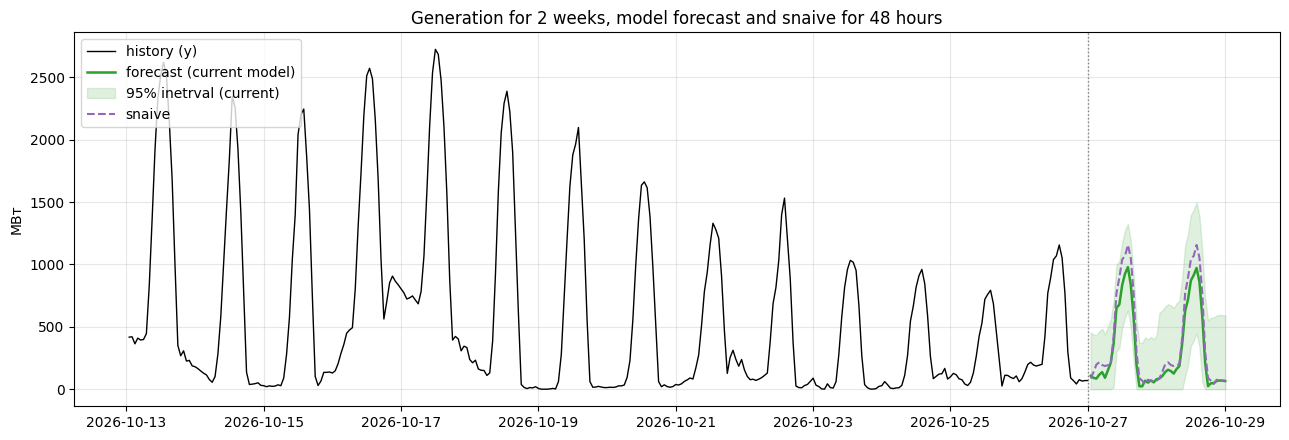

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sub_df_old = pd.read_csv("/content/YEFIMOVA_project.csv", parse_dates=["ds"]).rename(
    columns={"mean": "forecast", "lo-95": "lower_95", "hi-95": "upper_95"})
sub_df_new = pd.read_csv("/content/YEFIMOVA_project (1).csv", parse_dates=["ds"])
hist = data.tail(14 * 24)                    # останні 2 тижні історії

# снаїв: кожна година наступних 48 годин = та сама година останньої доби історії
last_day = data["y"].to_numpy(float)[-24:]
snaive_point = np.array([last_day[i % 24] for i in range(48)])

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="history (y)")
#ax.plot(sub_df_old["ds"], sub_df_old["forecast"], color="tab:blue", lw=1.8, label="прогноз (стара модель)")
# ax.fill_between(sub_df_old["ds"], sub_df_old["lower_95"], sub_df_old["upper_95"],
#                 color="tab:blue", alpha=0.15, label="95% інтервал (стара)")
ax.plot(sub_df_new["ds"], sub_df_new["forecast"], color="tab:green", lw=1.8, label="forecast (current model)")
ax.fill_between(sub_df_new["ds"], sub_df_new["lower_95"], sub_df_new["upper_95"],
                color="tab:green", alpha=0.15, label="95% inetrval (current)")
ax.plot(sub_df_new["ds"], snaive_point, color="tab:purple", lw=1.5, ls="--", label="snaive")
ax.axvline(hist["ds"].iloc[-1], color="grey", ls=":", lw=1)
ax.set_ylabel("МВт")
ax.set_title("Generation for 2 weeks, model forecast and snaive for 48 hours")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
hw_matrix = VARIANTS["персистентна"]
PB["SARIMA, 10 днів, шум 0.0x"] = empirical_bands(
    collect_point(lambda o: sarima_hw(o, 10, 0.0)))

cmp10 = {"7 днів": PB["SARIMA, персистентна, шум 0.0x"],
         "10 днів": PB["SARIMA, 10 днів, шум 0.0x"],
         "Наївний": PB["Наївний"]}
t, n = compare_models(cmp10)
print(f"спільних вікон: {n}")
display(t.round(3).sort_values("Winkler"))

спільних вікон: 6


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
7 днів,224.998,989.457,0.955,0.005,811.074,-42.521,71.286,0.667
10 днів,269.170,1263.885,0.941,0.009,938.361,1.650,105.913,0.667
Наївний,267.520,1563.810,0.944,0.006,1036.890,0.000,0.000,0.000


In [27]:
from scipy.special import inv_boxcox

LAM_BC, SHIFT_BC = 0.19, 1

def bc_fwd(v):
    return ((np.asarray(v, float) + SHIFT_BC) ** LAM_BC - 1) / LAM_BC

def bc_inv(t):
    return inv_boxcox(np.asarray(t, float), LAM_BC) - SHIFT_BC

def sarima_hw_bc(o, td=7, scale=0.0):
    m = ARIMA(order=(3, 0, 0), seasonal_order=(0, 1, 3), season_length=M)
    m.fit(y=bc_fwd(Y_full[o - 24 * td:o]), X=W_full[o - 24 * td:o])
    out = m.predict(h=H, X=hw_matrix(o, noisy_forecast(o, scale)))
    return np.clip(bc_inv(out["mean"]), 0, None)

hw_matrix = VARIANTS["персистентна"]
PB["SARIMA, BoxCox, персистентна, шум 0.0x"] = empirical_bands(
    collect_point(lambda o: sarima_hw_bc(o, 7, 0.0)))

cmpbc = {"SARIMA, персистентна (сира y)": PB["SARIMA, персистентна, шум 0.0x"],
         "SARIMA, BoxCox, персистентна": PB["SARIMA, BoxCox, персистентна, шум 0.0x"],
         "Наївний": PB["Наївний"]}
t, n = compare_models(cmpbc)
print(f"спільних вікон: {n}")
display(t.round(3).sort_values("Winkler"))
print("свіжі 5:")
display(compare_models({k: sub(v) for k, v in cmpbc.items()})[0].round(3))

спільних вікон: 6


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"SARIMA, персистентна (сира y)",224.998,989.457,0.955,0.005,811.074,-42.521,71.286,0.667
Наївний,267.520,1563.810,0.944,0.006,1036.890,0.000,0.000,0.000
"SARIMA, BoxCox, персистентна",306.097,2042.592,0.920,0.030,1208.283,38.578,148.542,0.333


свіжі 5:


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"SARIMA, персистентна (сира y)",214.620,970.412,0.962,0.013,806.643,-28.539,80.599,0.6
"SARIMA, BoxCox, персистентна",249.083,1410.084,0.979,0.029,1274.897,5.924,164.173,0.4
Наївний,243.160,1181.413,0.979,0.029,1113.992,0.000,0.000,0.0


In [28]:
def hw_blend(p, W_fc, w=0.5):
    # день 2: w * прогноз + (1 - w) * остання відома погода
    Wq = W_fc.copy()
    Wq[24:] = w * W_fc[24:] + (1 - w) * W_full[p - 1]
    return Wq

results = {}
for w in [0.0, 0.5, 1.0]:
    for scale in [0.0, 2.0]:
        hw_matrix = lambda p, W, w=w: hw_blend(p, W, w)
        PB[f"SARIMA, блend w={w}, шум {scale}x"] = empirical_bands(
            collect_point(lambda o, s=scale: sarima_hw(o, 7, s)))

rows = {k: sub(PB[k]) for k in PB if k.startswith("SARIMA, блend")}
rows["Наївний"] = sub(PB["Наївний"])
t, n = compare_models(rows)
print(f"спільних вікон: {n} з {N_RECENT}")
display(t.round(3).sort_values("Winkler"))

спільних вікон: 5 з 5


,RMSE,Winkler,покриття,|покриття−0.95|,"ширина, МВт",Δ RMSE vs наївний,±95% Δ,частка вікон краще наївного
модель,,,,,,,,
"SARIMA, блend w=0.0, шум 0.0x",214.620,970.412,0.962,0.013,806.643,-28.539,80.599,0.6
"SARIMA, блend w=0.0, шум 2.0x",217.703,972.295,0.962,0.013,824.108,-25.456,72.211,0.6
"SARIMA, блend w=0.5, шум 0.0x",212.351,991.152,0.950,0.000,787.715,-30.808,82.560,0.6
"SARIMA, блend w=1.0, шум 0.0x",211.916,1011.762,0.942,0.008,763.188,-31.244,83.513,0.8
"SARIMA, блend w=0.5, шум 2.0x",233.042,1050.485,0.958,0.008,890.074,-10.118,66.136,0.6
"SARIMA, блend w=1.0, шум 2.0x",264.301,1156.217,0.971,0.021,1040.164,21.141,62.620,0.2
Наївний,243.160,1181.413,0.979,0.029,1113.992,0.000,0.000,0.0


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

In [ ]:
forecast, lower_95, upper_95 = snaive(y)     # <-- replace with your model's forecast and 95% interval

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [ ]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.